In [ ]:
# Install necessary libraries
!pip install nltk gensim tensorflow scikit-learn matplotlib seaborn pandas numpy

# Standard library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

# NLP imports
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec

# Machine Learning imports
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

# Deep Learning imports
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, GRU, SimpleRNN, Embedding, Bidirectional, GlobalAveragePooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Download NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')



[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
# Load the datasets
train_df = pd.read_csv('/kaggle/input/datasets/mazharul2wizard/news-headline-training-testing/Training_data_2 - Training_data_2.csv')
test_df = pd.read_csv('/kaggle/input/datasets/mazharul2wizard/news-headline-training-testing/Test_data - Test_data.csv')

# Display basic information
print("Training Data Info:")
print(train_df.info())
print("\nTest Data Info:")
print(test_df.info())

# Show the first few rows
train_df.head(3)

Training Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105710 entries, 0 to 105709
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   News Headline  105710 non-null  object
 1   News Topic     105710 non-null  object
dtypes: object(2)
memory usage: 1.6+ MB
None

Test Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   News Headline  12000 non-null  object
 1   News Topic     12000 non-null  object
dtypes: object(2)
memory usage: 187.6+ KB
None


,News Headline,News Topic
0,<html> <body> News Headlines:\n <br> <b> US In...,Business
1,<html> <body> News Headlines:\n <br> <b> Repor...,Business
2,<html> <body> News Headlines:\n <br> <b> PITCA...,World News


## Exploratory Data Analysis (EDA)
Before preprocessing, we analyze the raw dataset to understand the class balance and identify common noise (like HTML tags) that needs to be removed.

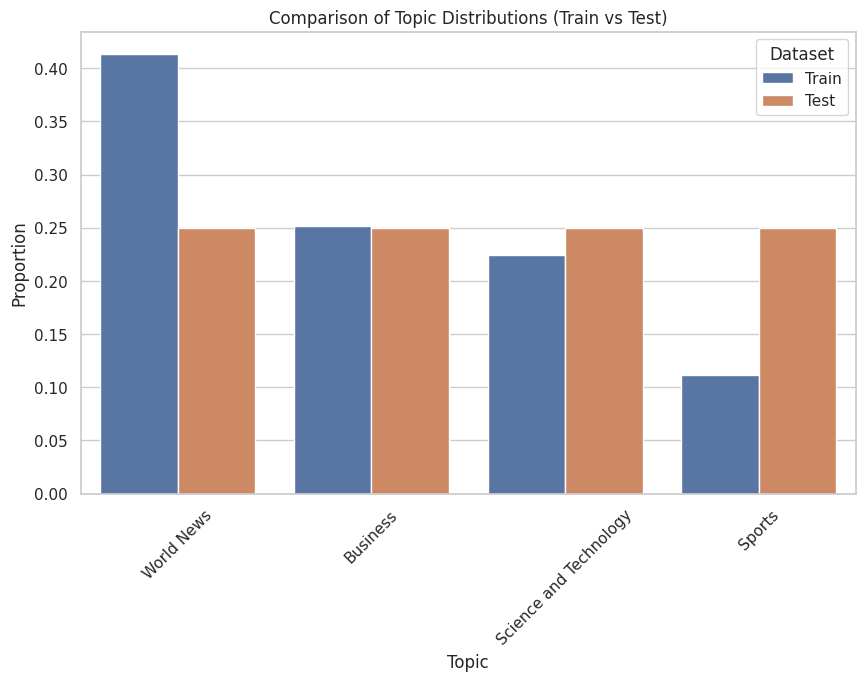

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

train_dist = train_df['News Topic'].value_counts(normalize=True)
test_dist = test_df['News Topic'].value_counts(normalize=True)

dist_df = pd.DataFrame({
    'Topic': train_dist.index,
    'Train': train_dist.values,
    'Test': test_dist.reindex(train_dist.index).values
}).melt(id_vars='Topic', var_name='Dataset', value_name='Proportion')

plt.figure(figsize=(10, 6))
sns.barplot(data=dist_df, x='Topic', y='Proportion', hue='Dataset')
plt.title('Comparison of Topic Distributions (Train vs Test)')
plt.xticks(rotation=45)
plt.show()

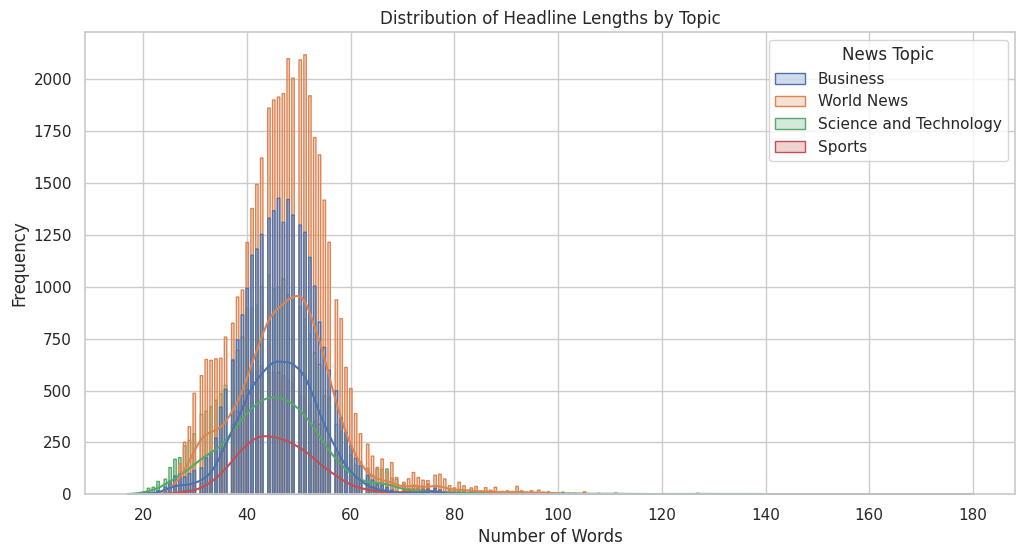

Average headline length per topic:
News Topic
Business                  46.559021
Science and Technology    46.187972
Sports                    46.683686
World News                47.860027
Name: headline_length, dtype: float64


In [ ]:
train_df['headline_length'] = train_df['News Headline'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(12, 6))
sns.histplot(data=train_df, x='headline_length', hue='News Topic', kde=True, element='step')
plt.title('Distribution of Headline Lengths by Topic')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

print("Average headline length per topic:")
print(train_df.groupby('News Topic')['headline_length'].mean())

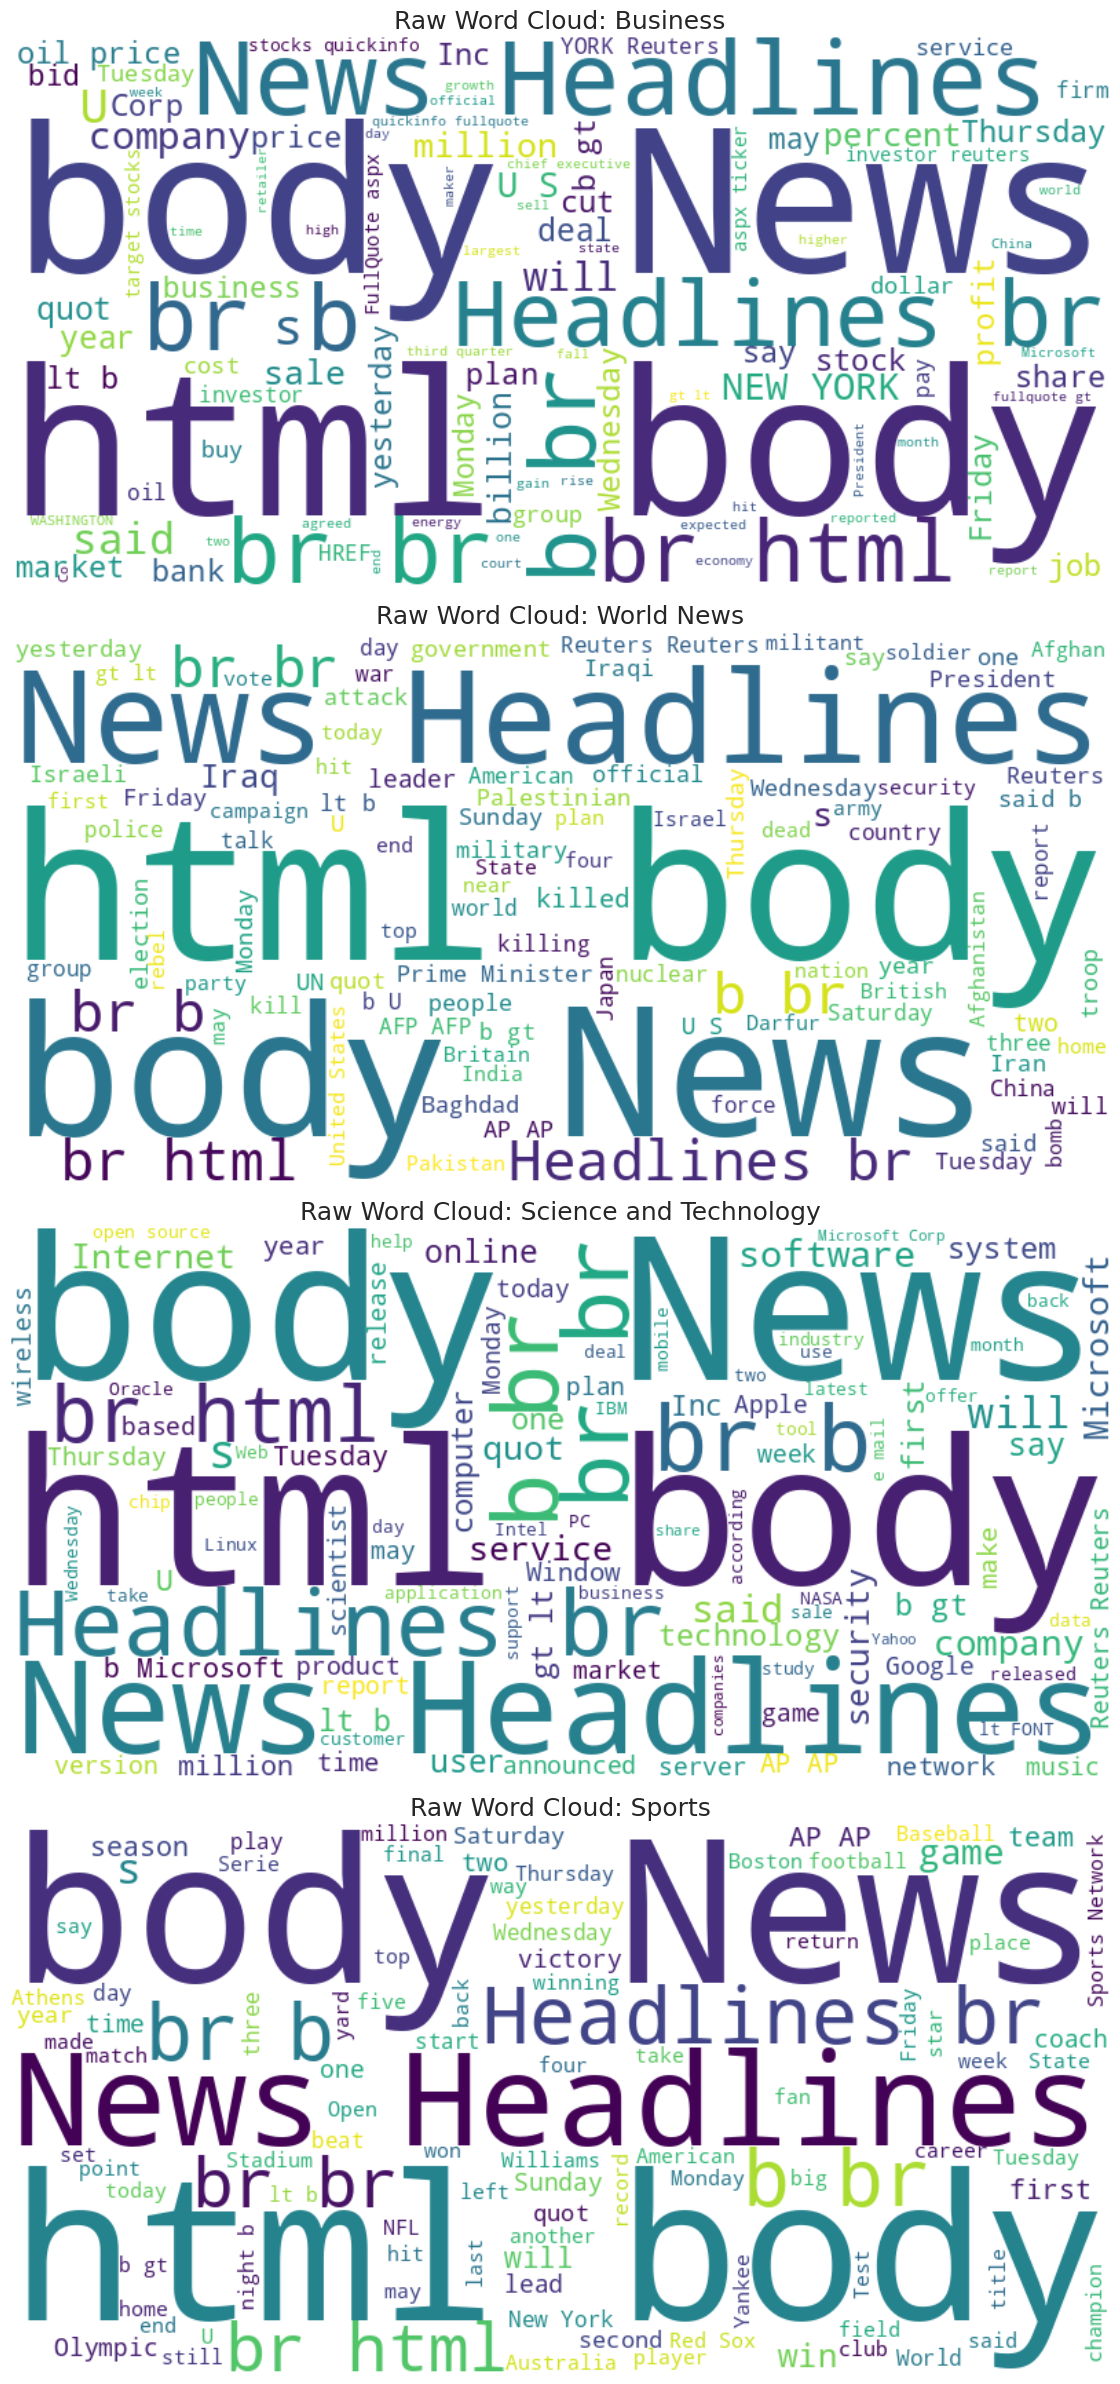

In [ ]:
from wordcloud import WordCloud

# 2. Word Clouds for Raw Data
# This will help us see HTML tags and punctuation that need cleaning
topics = train_df['News Topic'].unique()
fig, axes = plt.subplots(len(topics), 1, figsize=(12, 6 * len(topics)))

for i, topic in enumerate(topics):
    # Combine headlines for this topic
    topic_text = " ".join(train_df[train_df['News Topic'] == topic]['News Headline'].astype(str).iloc[:1000])

    wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(topic_text)

    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f'Raw Word Cloud: {topic}', fontsize=18)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Create a regex pattern for all punctuation
punc_pattern = re.compile('[%s]' % re.escape(string.punctuation))

def clean_html(text):
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def extreme_preprocess(text):
    text = clean_html(text)
    text = text.lower()

    # Use Regex instead of loops for punctuation removal
    text = punc_pattern.sub('', text)

    tokens = word_tokenize(text)
    tokens = [stemmer.stem(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

def optimum_preprocess(text):
    text = clean_html(text)
    text = text.lower()

    # Use Regex instead of loops for punctuation removal
    text = punc_pattern.sub('', text)

    tokens = word_tokenize(text)
    # Apply lemmatization instead of stemming
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

# 1. Dataset with No Preprocessing
train_no = train_df.copy()
test_no = test_df.copy()

# 2. Dataset with Extreme Preprocessing
train_extreme = train_df.copy()
test_extreme = test_df.copy()
train_extreme['News Headline'] = train_extreme['News Headline'].apply(extreme_preprocess)
test_extreme['News Headline'] = test_extreme['News Headline'].apply(extreme_preprocess)

# 3. Dataset with Optimum Preprocessing
train_opt = train_df.copy()
test_opt = test_df.copy()
train_opt['News Headline'] = train_opt['News Headline'].apply(optimum_preprocess)
test_opt['News Headline'] = test_opt['News Headline'].apply(optimum_preprocess)

[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### Comprehensive Vectorization and Scaling
We will now apply TF-IDF and StandardScaler to all three datasets (No Preprocessing, Extreme, and Optimum) and split them using stratification to handle the class imbalance.

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Mapping datasets for iteration
datasets_map = {
    'No Preprocessing': (train_no, test_no),
    'Extreme Preprocessing': (train_extreme, test_extreme),
    'Optimum Preprocessing': (train_opt, test_opt)
}

processed_data = {}
le = LabelEncoder()

# Standardize labels once (they are the same across datasets)
y_train_labels = le.fit_transform(train_df['News Topic'])
y_test_labels = le.transform(test_df['News Topic'])

with tf.device('/device:GPU:0'):
  for name, (train_data, test_data) in datasets_map.items():
      print(f"Processing: {name}...")

      # 1. TF-IDF
      tfidf = TfidfVectorizer(max_features=5000)
      X_train_tfidf = tfidf.fit_transform(train_data['News Headline'])
      X_test_tfidf = tfidf.transform(test_data['News Headline'])

      # 2. Scaling (with_mean=False for sparse matrices)
      scaler = StandardScaler(with_mean=False)
      X_train_scaled = scaler.fit_transform(X_train_tfidf)
      X_test_scaled = scaler.transform(X_test_tfidf)

      # 3. Stratified Split (80% Train, 20% Val)
      X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
          X_train_scaled,
          y_train_labels,
          test_size=0.2,
          random_state=42,
          stratify=y_train_labels
      )

      # Store results in a dictionary for easy access later
      processed_data[name] = {
          'X_train': X_train_split,
          'X_val': X_val_split,
          'X_test': X_test_scaled,
          'y_train': y_train_split,
          'y_val': y_val_split,
          'y_test': y_test_labels
      }

print("\nAll datasets vectorized, scaled, and split successfully.")

Processing: No Preprocessing...
Processing: Extreme Preprocessing...
Processing: Optimum Preprocessing...

All datasets vectorized, scaled, and split successfully.


--- Evaluating Baseline on: No Preprocessing ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Classification Report for No Preprocessing:
                        precision    recall  f1-score   support

              Business       0.75      0.88      0.81      3000
Science and Technology       0.90      0.71      0.79      3000
                Sports       0.95      0.82      0.88      3000
            World News       0.77      0.90      0.83      3000

              accuracy                           0.83     12000
             macro avg       0.84      0.83      0.83     12000
          weighted avg       0.84      0.83      0.83     12000



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


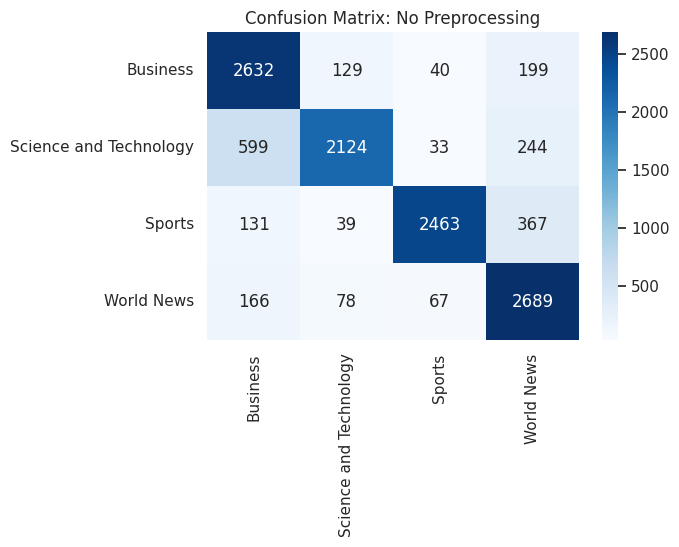

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


--- Evaluating Baseline on: Extreme Preprocessing ---
Classification Report for Extreme Preprocessing:
                        precision    recall  f1-score   support

              Business       0.83      0.84      0.84      3000
Science and Technology       0.86      0.83      0.84      3000
                Sports       0.93      0.87      0.90      3000
            World News       0.82      0.88      0.85      3000

              accuracy                           0.86     12000
             macro avg       0.86      0.86      0.86     12000
          weighted avg       0.86      0.86      0.86     12000



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


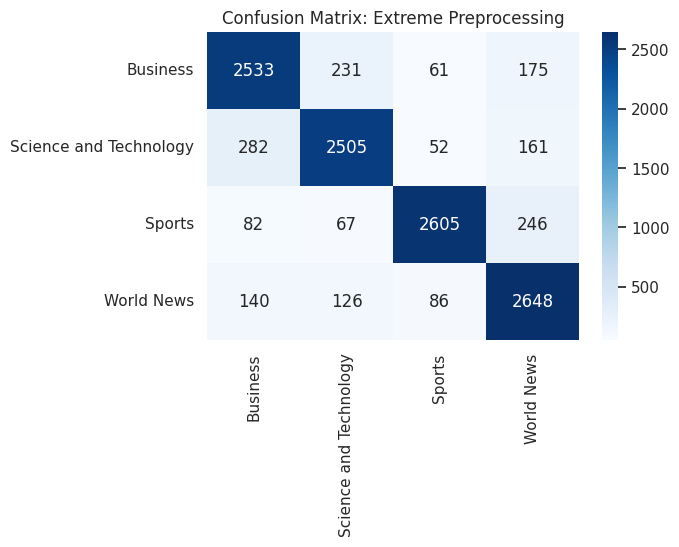

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


--- Evaluating Baseline on: Optimum Preprocessing ---
Classification Report for Optimum Preprocessing:
                        precision    recall  f1-score   support

              Business       0.83      0.84      0.84      3000
Science and Technology       0.85      0.83      0.84      3000
                Sports       0.92      0.87      0.89      3000
            World News       0.82      0.88      0.85      3000

              accuracy                           0.85     12000
             macro avg       0.86      0.85      0.86     12000
          weighted avg       0.86      0.85      0.86     12000



/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


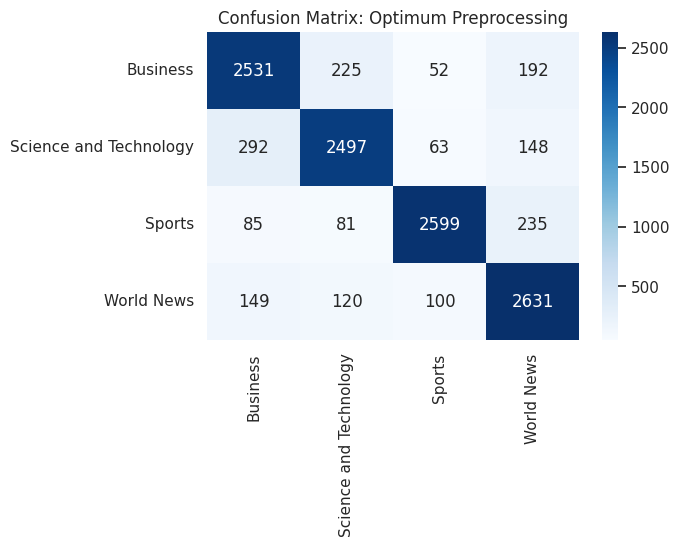

,Preprocessing,Model,Accuracy,F1-Macro
0,No Preprocessing,Logistic Regression,0.825667,0.826029
1,Extreme Preprocessing,Logistic Regression,0.857583,0.857974
2,Optimum Preprocessing,Logistic Regression,0.854833,0.855205


In [ ]:
all_results = []
with tf.device('/device:GPU:0'):
  for name, data in processed_data.items():
      print(f"--- Evaluating Baseline on: {name} ---")

      # Initialize and train
      lr_model = LogisticRegression(max_iter=1000, multi_class='multinomial',solver='saga')
      lr_model.fit(data['X_train'], data['y_train'])

      # Predict
      y_pred = lr_model.predict(data['X_test'])

      # Metrics
      acc = accuracy_score(data['y_test'], y_pred)
      f1 = f1_score(data['y_test'], y_pred, average='macro')

      # Store in master results list
      all_results.append({
          'Preprocessing': name,
          'Model': 'Logistic Regression',
          'Accuracy': acc,
          'F1-Macro': f1
      })

      print(f"Classification Report for {name}:")
      print(classification_report(data['y_test'], y_pred, target_names=le.classes_))

      cm = confusion_matrix(data['y_test'], y_pred)
      plt.figure(figsize=(6, 4))
      sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                  xticklabels=le.classes_, yticklabels=le.classes_)
      plt.title(f'Confusion Matrix: {name}')
      plt.show()

# Display current summary
display(pd.DataFrame(all_results))

In [ ]:
print(all_results)

[{'Preprocessing': 'No Preprocessing', 'Model': 'Logistic Regression', 'Accuracy': 0.8256666666666667, 'F1-Macro': 0.8260294496641036}, {'Preprocessing': 'Extreme Preprocessing', 'Model': 'Logistic Regression', 'Accuracy': 0.8575833333333334, 'F1-Macro': 0.8579736810939997}, {'Preprocessing': 'Optimum Preprocessing', 'Model': 'Logistic Regression', 'Accuracy': 0.8548333333333333, 'F1-Macro': 0.8552047630155603}]



--- Training DNN on: No Preprocessing ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.6884 - loss: 0.7797 - val_accuracy: 0.8992 - val_loss: 0.2952
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9078 - loss: 0.2943 - val_accuracy: 0.9082 - val_loss: 0.2745
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9292 - loss: 0.2240 - val_accuracy: 0.9150 - val_loss: 0.2632
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9465 - loss: 0.1731 - val_accuracy: 0.9185 - val_loss: 0.2572
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9600 - loss: 0.1293 - val_accuracy: 0.9202 - val_loss: 0.2710
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9706 - loss: 0.0989 - val_accuracy: 0.9220 - val_loss: 0.3238
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9768 - loss: 0.0769 - val_accuracy: 0.9191 - val_loss: 0.3198
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9806 - loss: 0.0665 - val_accuracy: 0

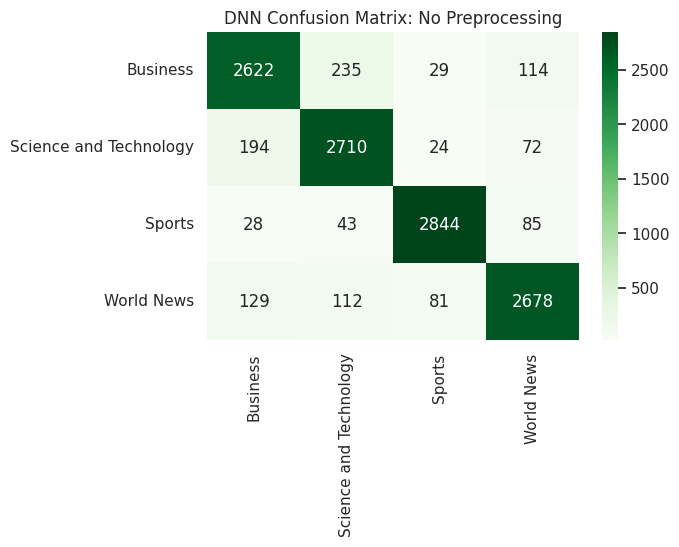


--- Training DNN on: Extreme Preprocessing ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.6815 - loss: 0.8110 - val_accuracy: 0.9006 - val_loss: 0.2963
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9069 - loss: 0.2980 - val_accuracy: 0.9091 - val_loss: 0.2718
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9256 - loss: 0.2311 - val_accuracy: 0.9157 - val_loss: 0.2623
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9414 - loss: 0.1806 - val_accuracy: 0.9185 - val_loss: 0.2586
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9544 - loss: 0.1484 - val_accuracy: 0.9225 - val_loss: 0.2655
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9646 - loss: 0.1153 - val_accuracy: 0.9249 - val_loss: 0.2843
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9718 - loss: 0.0913 - val_accuracy: 0.9245 - val_loss: 0.2978
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9770 - loss: 0.0739 - val_accuracy: 0

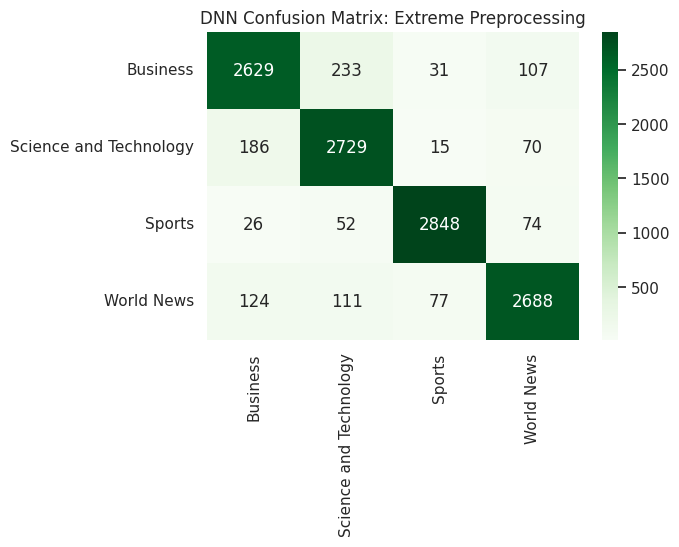


--- Training DNN on: Optimum Preprocessing ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.6825 - loss: 0.8009 - val_accuracy: 0.8990 - val_loss: 0.3021
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9078 - loss: 0.2941 - val_accuracy: 0.9081 - val_loss: 0.2688
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9281 - loss: 0.2271 - val_accuracy: 0.9133 - val_loss: 0.2642
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9435 - loss: 0.1792 - val_accuracy: 0.9194 - val_loss: 0.2518
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9565 - loss: 0.1451 - val_accuracy: 0.9198 - val_loss: 0.2633
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9675 - loss: 0.1097 - val_accuracy: 0.9231 - val_loss: 0.2812
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9736 - loss: 0.0899 - val_accuracy: 0.9237 - val_loss: 0.2961
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9803 - loss: 0.0687 - val_accuracy: 0

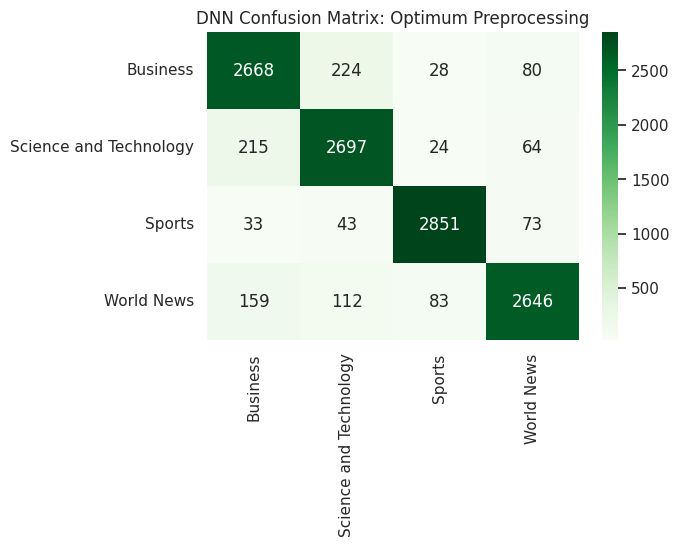

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import RMSprop

with tf.device('/device:GPU:0'):
  for i in all_results[:]:
    if i['Model'] == 'Deep Neural Network':
      all_results.remove(i)
  for name, data in processed_data.items():
      print(f"\n--- Training DNN on: {name} ---")

      model_dnn = Sequential([
          Dense(256, activation='relu', input_shape=(5000,)),
          Dropout(0.3),
          Dense(128, activation='relu'),
          Dropout(0.3),
          Dense(64, activation='relu'),
          Dropout(0.3),
          Dense(32, activation='relu'),
          Dropout(0.2),
          Dense(4, activation='softmax')
      ])
      opt=RMSprop(learning_rate=0.001)

      model_dnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
      es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5, restore_best_weights=True)

      model_dnn.fit(
          data['X_train'].toarray(),
          data['y_train'],
          validation_data=(data['X_val'].toarray(), data['y_val']),
          epochs=50,
          batch_size=256,
          callbacks=[es],
          verbose=1
      )

      y_probs = model_dnn.predict(data['X_test'].toarray())
      y_pred = np.argmax(y_probs, axis=1)

      acc = accuracy_score(data['y_test'], y_pred)
      f1 = f1_score(data['y_test'], y_pred, average='macro')

      all_results.append({
          'Preprocessing': name,
          'Model': 'Deep Neural Network',
          'Accuracy': acc,
          'F1-Macro': f1
      })

      print(f"\nFinal Metrics for DNN ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
      print(classification_report(data['y_test'], y_pred, target_names=le.classes_))

      cm = confusion_matrix(data['y_test'], y_pred)
      plt.figure(figsize=(6, 4))
      sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
      plt.title(f'DNN Confusion Matrix: {name}')
      plt.show()

In [ ]:
# Compare Logistic Regression vs Deep Neural Network
comparison_df = pd.DataFrame(all_results)
print("Comparison of Model Evaluation Metrics:")
display(comparison_df)

Comparison of Model Evaluation Metrics:


,Preprocessing,Model,Accuracy,F1-Macro
0,No Preprocessing,Logistic Regression,0.825667,0.826029
1,Extreme Preprocessing,Logistic Regression,0.857583,0.857974
2,Optimum Preprocessing,Logistic Regression,0.854833,0.855205
3,No Preprocessing,Deep Neural Network,0.904500,0.904571
4,Extreme Preprocessing,Deep Neural Network,0.907833,0.907931
5,Optimum Preprocessing,Deep Neural Network,0.905167,0.905319


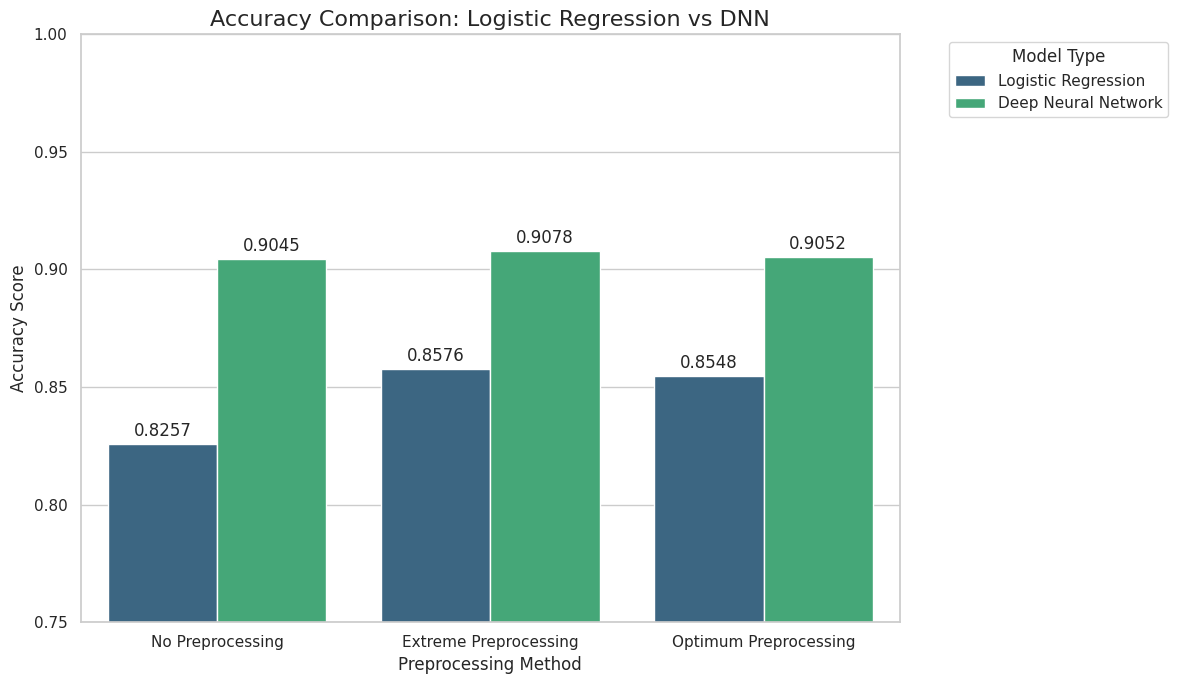

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the DataFrame from all_results
comparison_df = pd.DataFrame(all_results)

# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Initialize the matplotlib figure
plt.figure(figsize=(12, 7))

# Create the barplot
ax = sns.barplot(
    data=comparison_df,
    x='Preprocessing',
    y='Accuracy',
    hue='Model',
    palette='viridis'
)

# Add titles and labels
plt.title('Accuracy Comparison: Logistic Regression vs DNN', fontsize=16)
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Preprocessing Method', fontsize=12)
plt.ylim(0.75, 1.0) # Zoom in to see differences more clearly

# Add data labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)

plt.legend(title='Model Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
from gensim.models import Word2Vec
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

embedding_dim = 100
max_words = 10000
max_len = 50

sequence_data = {}

text_datasets = {
    'No Preprocessing': (train_no, test_no),
    'Extreme Preprocessing': (train_extreme, test_extreme),
    'Optimum Preprocessing': (train_opt, test_opt)
}

def simple_split(text):
    return str(text).split()   # IMPORTANT: keep consistent with your preprocessing

with tf.device('/device:GPU:0'):
    for name, (train_data, test_data) in text_datasets.items():

        print(f"\n--- Processing: {name} ---")

        # 🔹 1. Train Skip-gram Word2Vec
        sentences = [simple_split(text) for text in train_data['News Headline']]

        w2v_model = Word2Vec(
            sentences=sentences,
            vector_size=embedding_dim,
            window=5,
            min_count=1,   # IMPORTANT FIX
            sg=1
        )

        # 🔹 2. Tokenizer (same text, no transformation mismatch)
        tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
        tokenizer.fit_on_texts(train_data['News Headline'])

        def get_sequences(text_series):
            seqs = tokenizer.texts_to_sequences(text_series)
            return pad_sequences(seqs, maxlen=max_len, padding='post', truncating='post')

        X_train_seq = get_sequences(train_data['News Headline'])
        X_test_seq = get_sequences(test_data['News Headline'])

        # 🔹 3. Build embedding matrix
        word_index = tokenizer.word_index
        num_words_actual = min(max_words, len(word_index) + 1)

        embedding_matrix = np.zeros((num_words_actual, embedding_dim))

        for word, i in word_index.items():
            if i >= max_words:
                continue
            if word in w2v_model.wv:
                embedding_matrix[i] = w2v_model.wv[word]

        sequence_data[name] = {
            'X_train': X_train_seq,
            'X_test': X_test_seq,
            'embedding_matrix': embedding_matrix,
            'num_words': num_words_actual
        }

        print(f"Embedding matrix shape: {embedding_matrix.shape}")


--- Processing: No Preprocessing ---
Embedding matrix shape: (10000, 100)

--- Processing: Extreme Preprocessing ---
Embedding matrix shape: (10000, 100)

--- Processing: Optimum Preprocessing ---
Embedding matrix shape: (10000, 100)



--- Training SimpleRNN on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.6138 - loss: 0.9255 - val_accuracy: 0.8307 - val_loss: 0.4861
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8409 - loss: 0.4587 - val_accuracy: 0.8525 - val_loss: 0.4186
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8595 - loss: 0.4017 - val_accuracy: 0.8671 - val_loss: 0.3848
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8715 - loss: 0.3702 - val_accuracy: 0.8653 - val_loss: 0.3923
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8794 - loss: 0.3481 - val_accuracy: 0.8739 - val_loss: 0.3528
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8916 - loss: 0.3153 - val_accuracy: 0.8806 - val_loss: 0.3444
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8959 - loss: 0.3020 - val_accuracy: 0.8853 - val_loss: 0.3290
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/

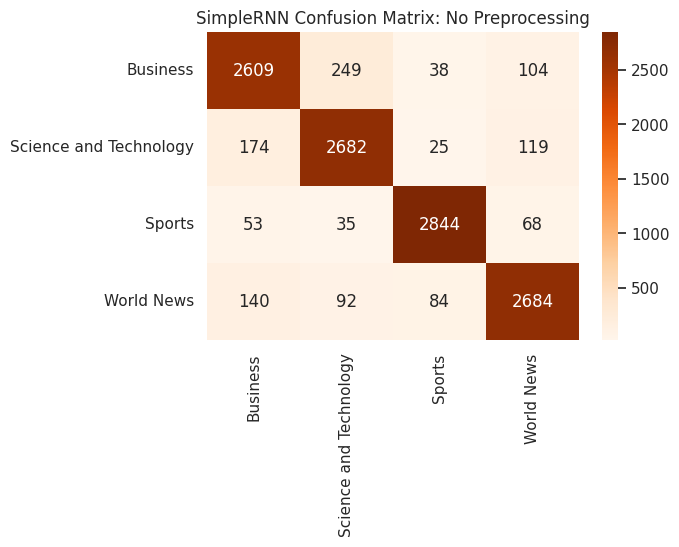


--- Training SimpleRNN on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.6631 - loss: 0.7947 - val_accuracy: 0.8740 - val_loss: 0.3715
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8781 - loss: 0.3602 - val_accuracy: 0.8819 - val_loss: 0.3563
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8872 - loss: 0.3269 - val_accuracy: 0.8925 - val_loss: 0.3127
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8963 - loss: 0.3038 - val_accuracy: 0.8846 - val_loss: 0.3252
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8991 - loss: 0.2928 - val_accuracy: 0.8972 - val_loss: 0.2995
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9036 - loss: 0.2806 - val_accuracy: 0.8993 - val_loss: 0.2924
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9083 - loss: 0.2660 - val_accuracy: 0.9021 - val_loss: 0.2827
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 

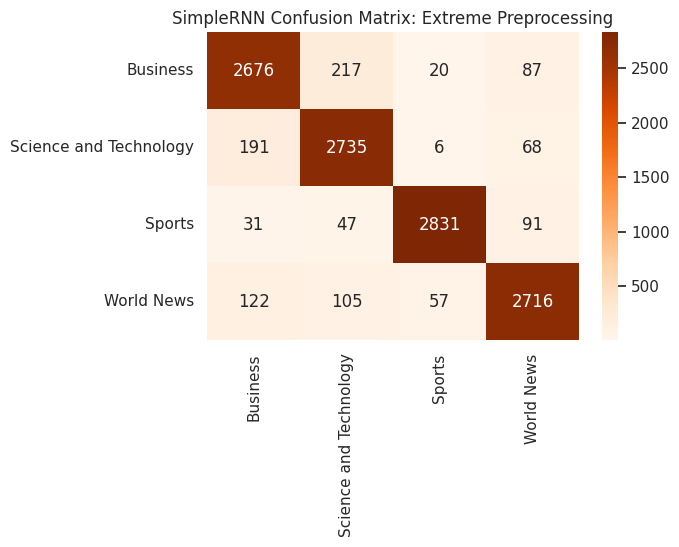


--- Training SimpleRNN on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.6698 - loss: 0.8214 - val_accuracy: 0.8646 - val_loss: 0.4084
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8723 - loss: 0.3830 - val_accuracy: 0.8796 - val_loss: 0.3527
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8834 - loss: 0.3397 - val_accuracy: 0.8826 - val_loss: 0.3400
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8920 - loss: 0.3126 - val_accuracy: 0.8897 - val_loss: 0.3218
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8966 - loss: 0.3006 - val_accuracy: 0.8924 - val_loss: 0.3081
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9005 - loss: 0.2865 - val_accuracy: 0.8963 - val_loss: 0.2977
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9047 - loss: 0.2719 - val_accuracy: 0.8964 - val_loss: 0.2996
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 3s 

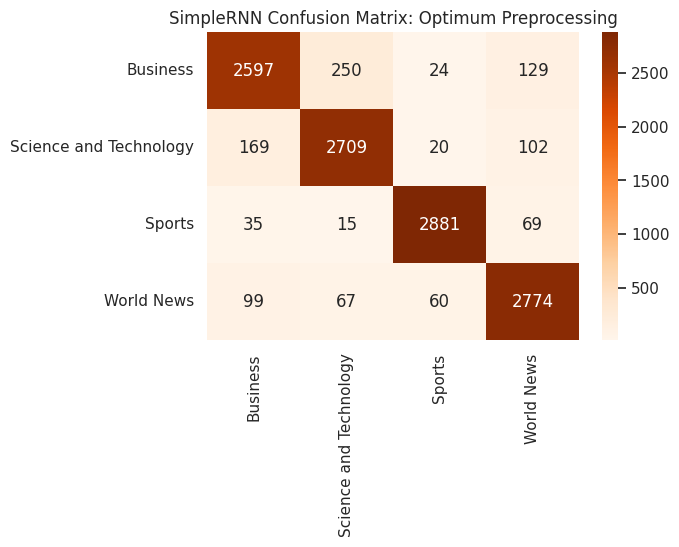

In [ ]:
from tensorflow.keras.layers import SimpleRNN
from tensorflow.keras.optimizers import Adam

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'SimpleRNN':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training SimpleRNN on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            SimpleRNN(256, activation='tanh'),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = Adam(learning_rate=0.0001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'SimpleRNN',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for SimpleRNN ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'SimpleRNN Confusion Matrix: {name}')
        plt.show()


--- Training GRU on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.6286 - loss: 0.9134 - val_accuracy: 0.8221 - val_loss: 0.5226
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8606 - loss: 0.4016 - val_accuracy: 0.8703 - val_loss: 0.3732
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8850 - loss: 0.3296 - val_accuracy: 0.8942 - val_loss: 0.2978
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8973 - loss: 0.2899 - val_accuracy: 0.8972 - val_loss: 0.2942
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9076 - loss: 0.2611 - val_accuracy: 0.9059 - val_loss: 0.2733
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9164 - loss: 0.2359 - val_accuracy: 0.9096 - val_loss: 0.2578
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9228 - loss: 0.2150 - val_accuracy: 0.9061 - val_loss: 0.2806
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step -

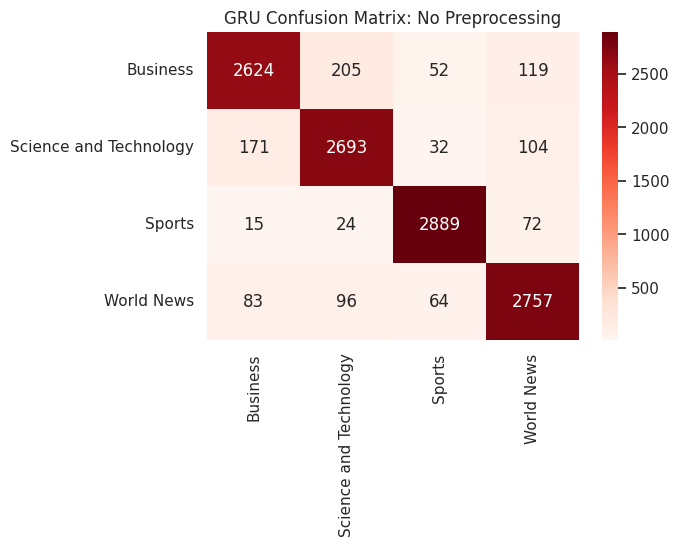


--- Training GRU on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.4108 - loss: 1.3034 - val_accuracy: 0.4251 - val_loss: 1.1329
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6740 - loss: 0.7042 - val_accuracy: 0.8585 - val_loss: 0.4606
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8801 - loss: 0.3666 - val_accuracy: 0.8842 - val_loss: 0.3526
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8947 - loss: 0.3086 - val_accuracy: 0.8949 - val_loss: 0.3004
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9043 - loss: 0.2777 - val_accuracy: 0.8935 - val_loss: 0.3045
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9118 - loss: 0.2567 - val_accuracy: 0.9014 - val_loss: 0.2835
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9166 - loss: 0.2385 - val_accuracy: 0.9066 - val_loss: 0.2676
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/s

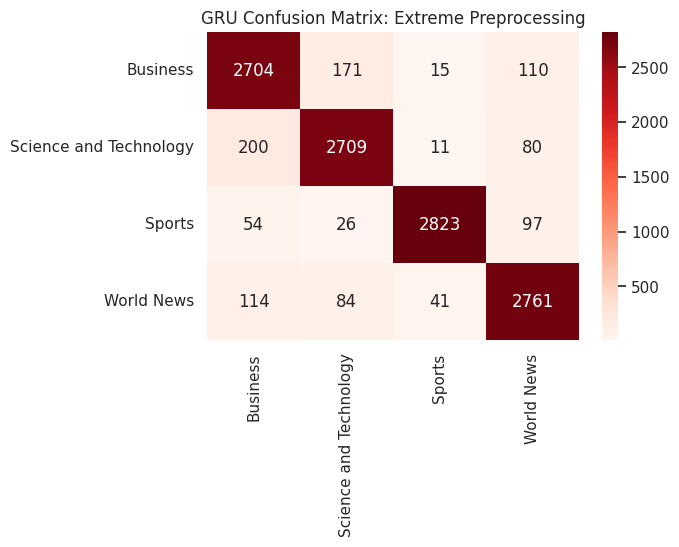


--- Training GRU on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.4290 - loss: 1.2636 - val_accuracy: 0.5901 - val_loss: 0.9368
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7083 - loss: 0.6347 - val_accuracy: 0.8624 - val_loss: 0.4030
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8881 - loss: 0.3394 - val_accuracy: 0.8702 - val_loss: 0.3502
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.8999 - loss: 0.2909 - val_accuracy: 0.8990 - val_loss: 0.2888
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9090 - loss: 0.2625 - val_accuracy: 0.8830 - val_loss: 0.3132
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9122 - loss: 0.2489 - val_accuracy: 0.9067 - val_loss: 0.2702
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9187 - loss: 0.2312 - val_accuracy: 0.8974 - val_loss: 0.2895
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/s

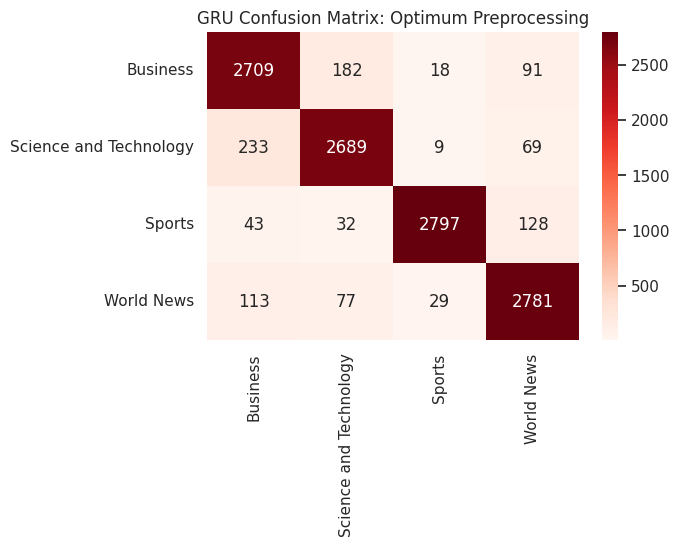

In [ ]:
from tensorflow.keras.layers import GRU
from tensorflow.keras.optimizers import RMSprop

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'GRU':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training GRU on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            GRU(256),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = RMSprop(learning_rate=0.001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'GRU',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for GRU ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'GRU Confusion Matrix: {name}')
        plt.show()


--- Training LSTM on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.6500 - loss: 0.8514 - val_accuracy: 0.8593 - val_loss: 0.4187
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8555 - loss: 0.4160 - val_accuracy: 0.8619 - val_loss: 0.4071
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8825 - loss: 0.3402 - val_accuracy: 0.8743 - val_loss: 0.3575
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8945 - loss: 0.3009 - val_accuracy: 0.8847 - val_loss: 0.3430
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9044 - loss: 0.2693 - val_accuracy: 0.9007 - val_loss: 0.2838
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9148 - loss: 0.2430 - val_accuracy: 0.9081 - val_loss: 0.2762
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9222 - loss: 0.2211 - val_accuracy: 0.9101 - val_loss: 0.2597
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step 

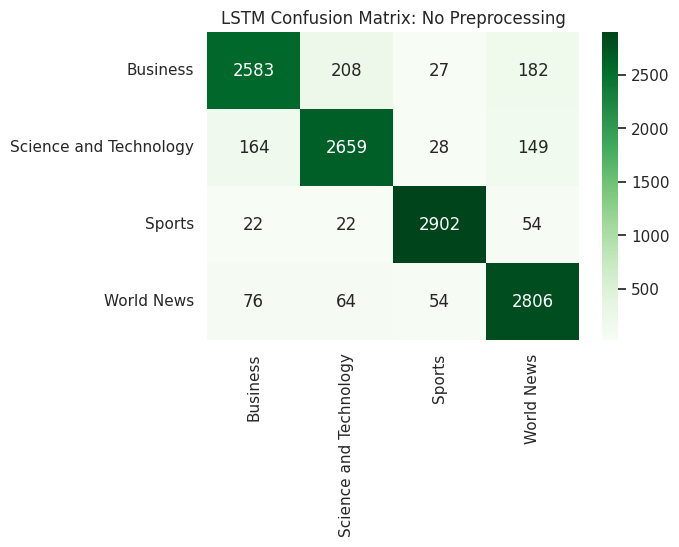


--- Training LSTM on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.5841 - loss: 0.9378 - val_accuracy: 0.8071 - val_loss: 0.5839
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8724 - loss: 0.3936 - val_accuracy: 0.8599 - val_loss: 0.4172
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8901 - loss: 0.3270 - val_accuracy: 0.8789 - val_loss: 0.3458
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9001 - loss: 0.2915 - val_accuracy: 0.9019 - val_loss: 0.2907
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9080 - loss: 0.2670 - val_accuracy: 0.9086 - val_loss: 0.2717
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9143 - loss: 0.2471 - val_accuracy: 0.8956 - val_loss: 0.3112
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9214 - loss: 0.2285 - val_accuracy: 0.9082 - val_loss: 0.2604
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/

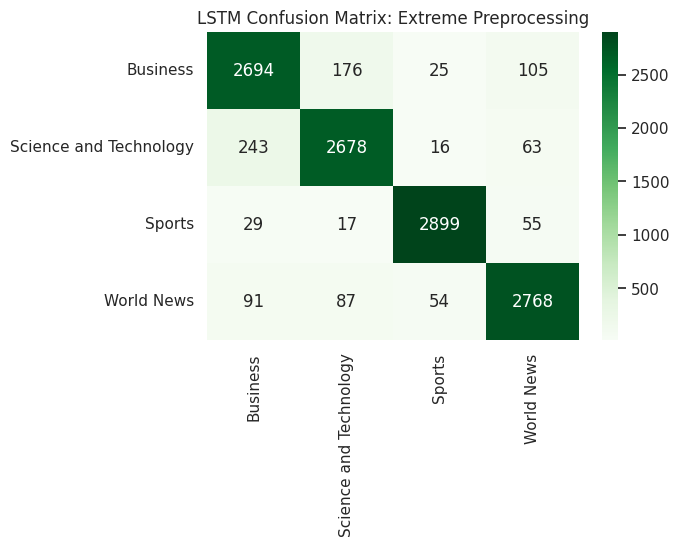


--- Training LSTM on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.6250 - loss: 0.8612 - val_accuracy: 0.8750 - val_loss: 0.3932
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8731 - loss: 0.3854 - val_accuracy: 0.8851 - val_loss: 0.3319
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.8909 - loss: 0.3196 - val_accuracy: 0.8864 - val_loss: 0.3106
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9024 - loss: 0.2840 - val_accuracy: 0.8748 - val_loss: 0.3685
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9122 - loss: 0.2618 - val_accuracy: 0.8858 - val_loss: 0.3166
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9159 - loss: 0.2443 - val_accuracy: 0.8725 - val_loss: 0.3496
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.9208 - loss: 0.2284 - val_accuracy: 0.9123 - val_loss: 0.2658
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/

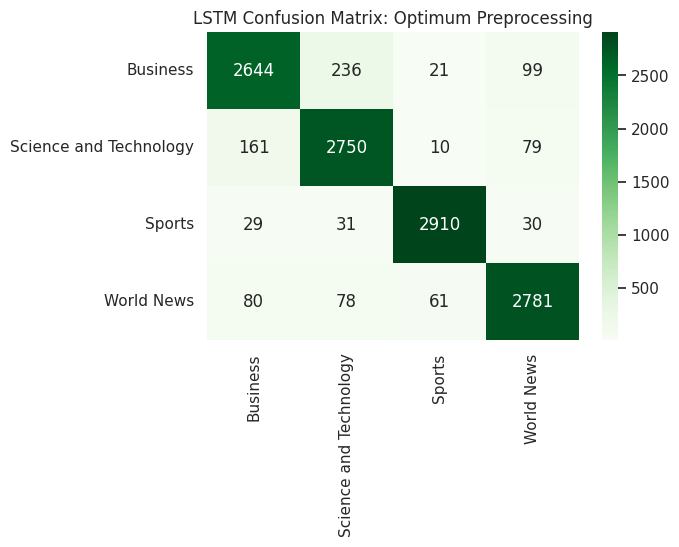

In [ ]:
from tensorflow.keras.layers import LSTM
from tensorflow.keras.optimizers import RMSprop

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'LSTM':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training LSTM on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            LSTM(256),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = RMSprop(learning_rate=0.001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'LSTM',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for LSTM ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'LSTM Confusion Matrix: {name}')
        plt.show()


--- Training Bidirectional SimpleRNN on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.7335 - loss: 0.6737 - val_accuracy: 0.8763 - val_loss: 0.3574
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8908 - loss: 0.3226 - val_accuracy: 0.8703 - val_loss: 0.3642
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9139 - loss: 0.2542 - val_accuracy: 0.8498 - val_loss: 0.4429
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9244 - loss: 0.2227 - val_accuracy: 0.8967 - val_loss: 0.3034
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9391 - loss: 0.1811 - val_accuracy: 0.9124 - val_loss: 0.2727
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9481 - loss: 0.1504 - val_accuracy: 0.9013 - val_loss: 0.3192
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9510 - loss: 0.1450 - val_accuracy: 0.9026 - val_loss: 0.3175
Epoch 8/50
331/331 ━━━━━━━━━━━━━━

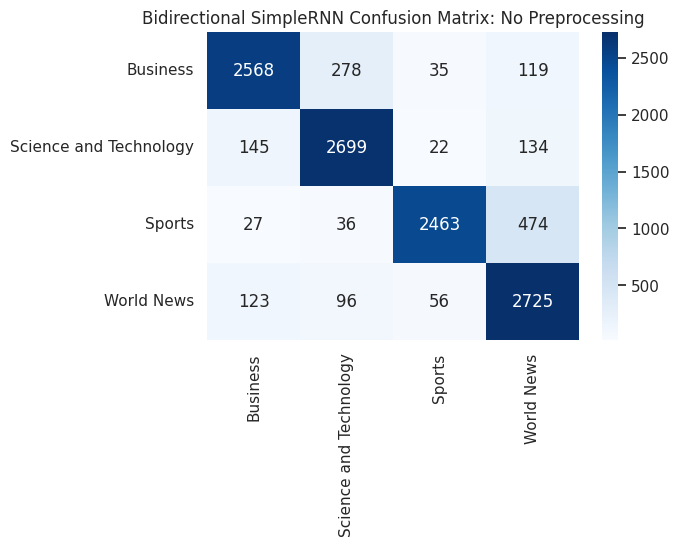


--- Training Bidirectional SimpleRNN on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8143 - loss: 0.5070 - val_accuracy: 0.8940 - val_loss: 0.3045
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9031 - loss: 0.2790 - val_accuracy: 0.9069 - val_loss: 0.2686
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9228 - loss: 0.2234 - val_accuracy: 0.9130 - val_loss: 0.2771
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9380 - loss: 0.1793 - val_accuracy: 0.9175 - val_loss: 0.2473
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9496 - loss: 0.1418 - val_accuracy: 0.9133 - val_loss: 0.2786
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9580 - loss: 0.1194 - val_accuracy: 0.9083 - val_loss: 0.2960
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9629 - loss: 0.1048 - val_accuracy: 0.9091 - val_loss: 0.3631
Epoch 8/50
331/331 ━━━━━━━━━

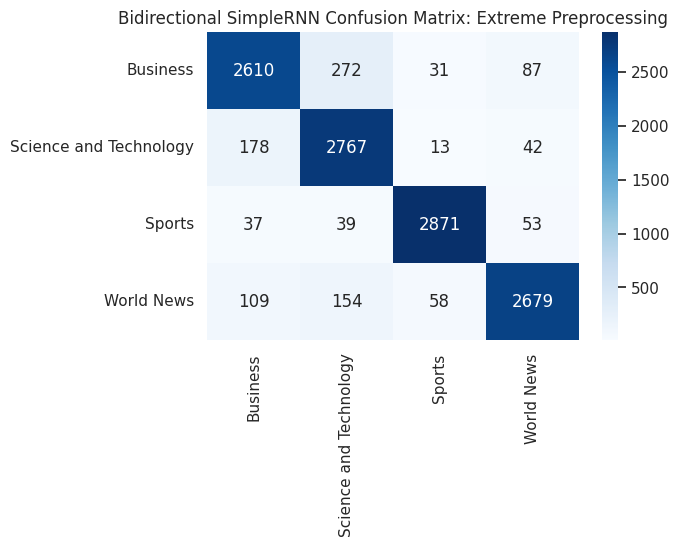


--- Training Bidirectional SimpleRNN on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.8048 - loss: 0.5123 - val_accuracy: 0.8931 - val_loss: 0.3058
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9039 - loss: 0.2793 - val_accuracy: 0.9011 - val_loss: 0.2843
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9202 - loss: 0.2293 - val_accuracy: 0.9029 - val_loss: 0.2882
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9353 - loss: 0.1917 - val_accuracy: 0.9160 - val_loss: 0.2630
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9509 - loss: 0.1446 - val_accuracy: 0.9136 - val_loss: 0.2735
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9566 - loss: 0.1251 - val_accuracy: 0.9133 - val_loss: 0.2905
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9606 - loss: 0.1139 - val_accuracy: 0.9151 - val_loss: 0.2846
Epoch 8/50
331/331 ━━━━━━━━━

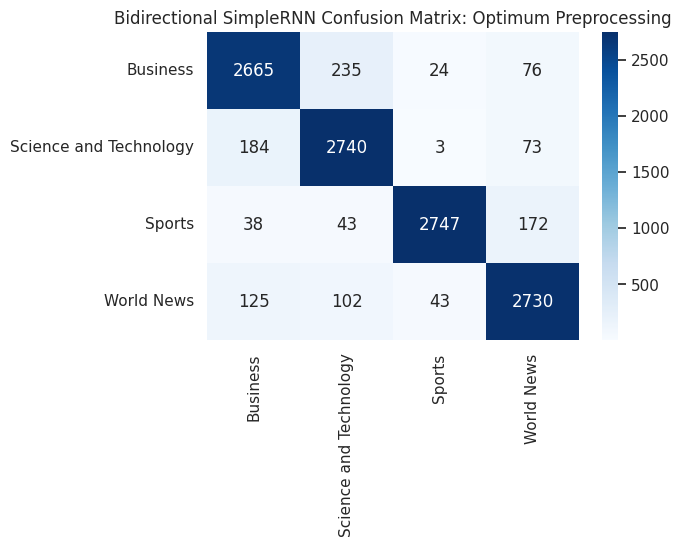

In [ ]:
from tensorflow.keras.layers import SimpleRNN, Bidirectional
from tensorflow.keras.optimizers import Adam

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'Bidirectional SimpleRNN':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training Bidirectional SimpleRNN on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            Bidirectional(SimpleRNN(256, activation='tanh')),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = Adam(learning_rate=0.001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'Bidirectional SimpleRNN',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for Bidirectional SimpleRNN ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'Bidirectional SimpleRNN Confusion Matrix: {name}')
        plt.show()


--- Training Bidirectional GRU on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.6134 - loss: 0.9294 - val_accuracy: 0.8229 - val_loss: 0.5155
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8585 - loss: 0.4099 - val_accuracy: 0.8777 - val_loss: 0.3489
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8826 - loss: 0.3362 - val_accuracy: 0.8822 - val_loss: 0.3525
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8986 - loss: 0.2917 - val_accuracy: 0.8932 - val_loss: 0.2983
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9089 - loss: 0.2613 - val_accuracy: 0.9045 - val_loss: 0.2656
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9151 - loss: 0.2404 - val_accuracy: 0.9091 - val_loss: 0.2529
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9219 - loss: 0.2208 - val_accuracy: 0.9142 - val_loss: 0.2411
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━━━━━━

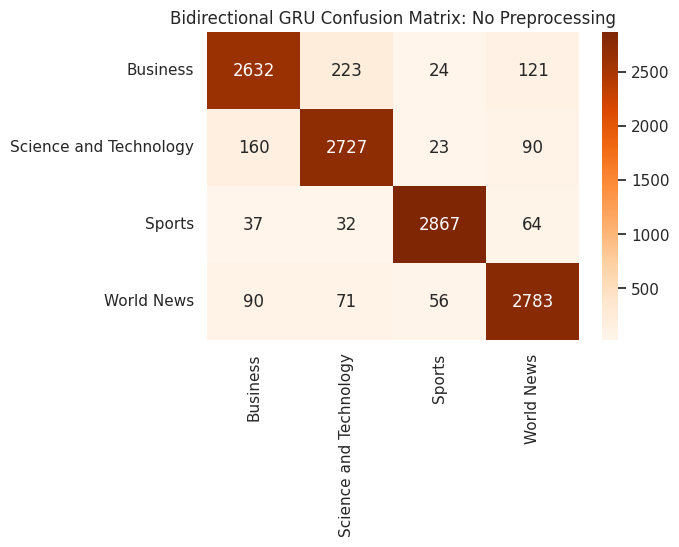


--- Training Bidirectional GRU on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7574 - loss: 0.6014 - val_accuracy: 0.8574 - val_loss: 0.3842
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8899 - loss: 0.3132 - val_accuracy: 0.8965 - val_loss: 0.2835
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9015 - loss: 0.2785 - val_accuracy: 0.9017 - val_loss: 0.2867
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9096 - loss: 0.2528 - val_accuracy: 0.9081 - val_loss: 0.2594
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9171 - loss: 0.2303 - val_accuracy: 0.9137 - val_loss: 0.2410
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9236 - loss: 0.2149 - val_accuracy: 0.9206 - val_loss: 0.2286
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9305 - loss: 0.1950 - val_accuracy: 0.9147 - val_loss: 0.2418
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━

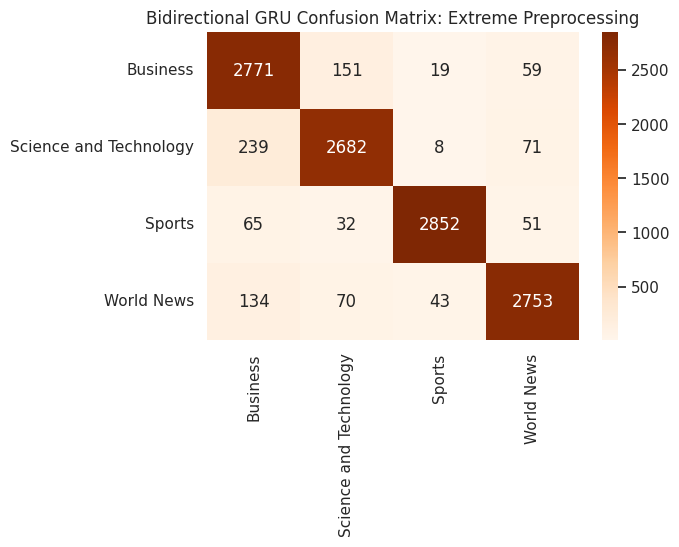


--- Training Bidirectional GRU on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.7517 - loss: 0.6114 - val_accuracy: 0.8473 - val_loss: 0.4201
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8861 - loss: 0.3178 - val_accuracy: 0.8905 - val_loss: 0.3071
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9017 - loss: 0.2763 - val_accuracy: 0.8792 - val_loss: 0.3338
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9103 - loss: 0.2510 - val_accuracy: 0.8902 - val_loss: 0.3031
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9153 - loss: 0.2360 - val_accuracy: 0.8981 - val_loss: 0.2869
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9205 - loss: 0.2173 - val_accuracy: 0.9133 - val_loss: 0.2452
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.9289 - loss: 0.1961 - val_accuracy: 0.9174 - val_loss: 0.2446
Epoch 8/50
331/331 ━━━━━━━━━━━━━━━

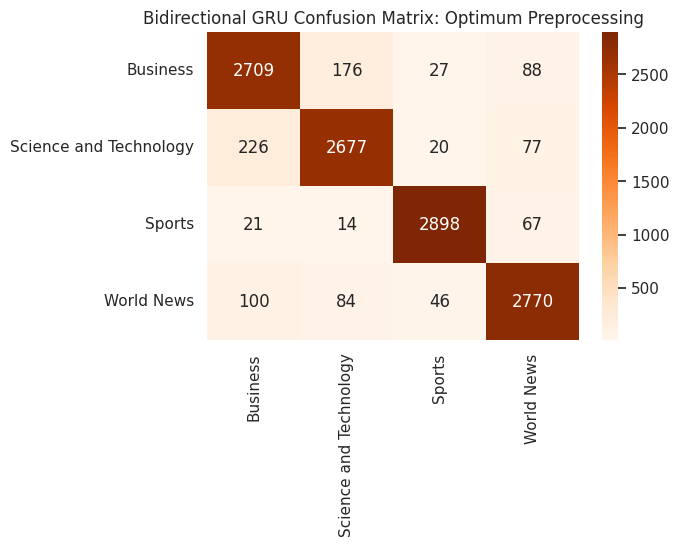

In [ ]:
from tensorflow.keras.layers import GRU, Bidirectional
from tensorflow.keras.optimizers import RMSprop

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'Bidirectional GRU':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training Bidirectional GRU on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            Bidirectional(GRU(256)),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = RMSprop(learning_rate=0.001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'Bidirectional GRU',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for Bidirectional GRU ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'Bidirectional GRU Confusion Matrix: {name}')
        plt.show()


--- Training Bidirectional LSTM on: No Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.6742 - loss: 0.8057 - val_accuracy: 0.8377 - val_loss: 0.4590
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8617 - loss: 0.3891 - val_accuracy: 0.8590 - val_loss: 0.4079
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8893 - loss: 0.3153 - val_accuracy: 0.8920 - val_loss: 0.3066
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9027 - loss: 0.2741 - val_accuracy: 0.9022 - val_loss: 0.2784
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9151 - loss: 0.2437 - val_accuracy: 0.8896 - val_loss: 0.3189
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9201 - loss: 0.2259 - val_accuracy: 0.9118 - val_loss: 0.2554
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9267 - loss: 0.2056 - val_accuracy: 0.8870 - val_loss: 0.3132
Epoch 8/50
331/331 ━━━━━━━━━━━━━

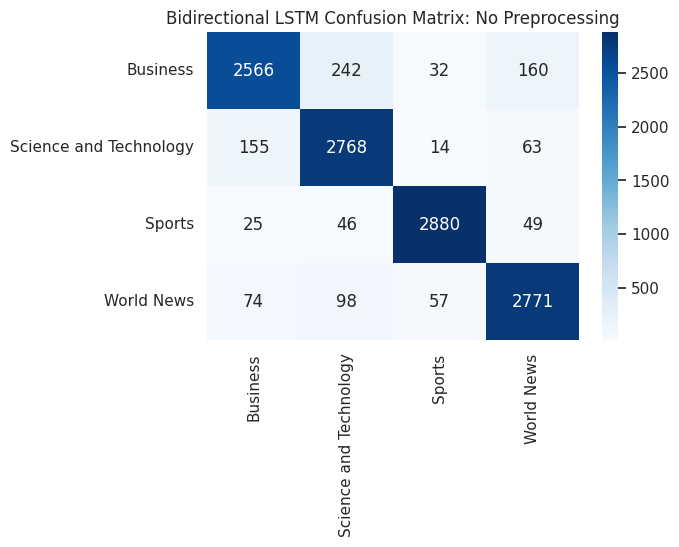


--- Training Bidirectional LSTM on: Extreme Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.7899 - loss: 0.5558 - val_accuracy: 0.8107 - val_loss: 0.4636
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8897 - loss: 0.3070 - val_accuracy: 0.9003 - val_loss: 0.2848
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9068 - loss: 0.2600 - val_accuracy: 0.9038 - val_loss: 0.2649
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9139 - loss: 0.2390 - val_accuracy: 0.9062 - val_loss: 0.2594
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9219 - loss: 0.2156 - val_accuracy: 0.9180 - val_loss: 0.2336
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9307 - loss: 0.1933 - val_accuracy: 0.9189 - val_loss: 0.2281
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9361 - loss: 0.1751 - val_accuracy: 0.9191 - val_loss: 0.2369
Epoch 8/50
331/331 ━━━━━━━━

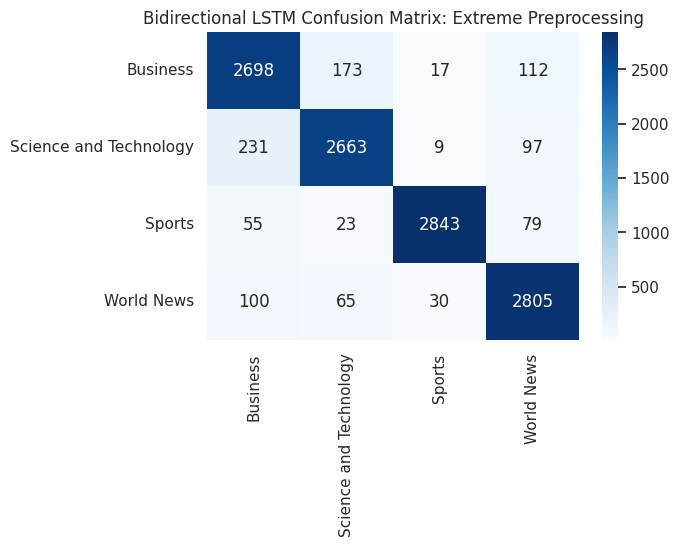


--- Training Bidirectional LSTM on: Optimum Preprocessing ---
Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.7848 - loss: 0.5670 - val_accuracy: 0.8780 - val_loss: 0.3429
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.8917 - loss: 0.3017 - val_accuracy: 0.8968 - val_loss: 0.2902
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9056 - loss: 0.2625 - val_accuracy: 0.8827 - val_loss: 0.3212
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9133 - loss: 0.2418 - val_accuracy: 0.9039 - val_loss: 0.2718
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9206 - loss: 0.2194 - val_accuracy: 0.9049 - val_loss: 0.2708
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9289 - loss: 0.1961 - val_accuracy: 0.9056 - val_loss: 0.2704
Epoch 7/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9350 - loss: 0.1797 - val_accuracy: 0.9237 - val_loss: 0.2198
Epoch 8/50
331/331 ━━━━━━━━

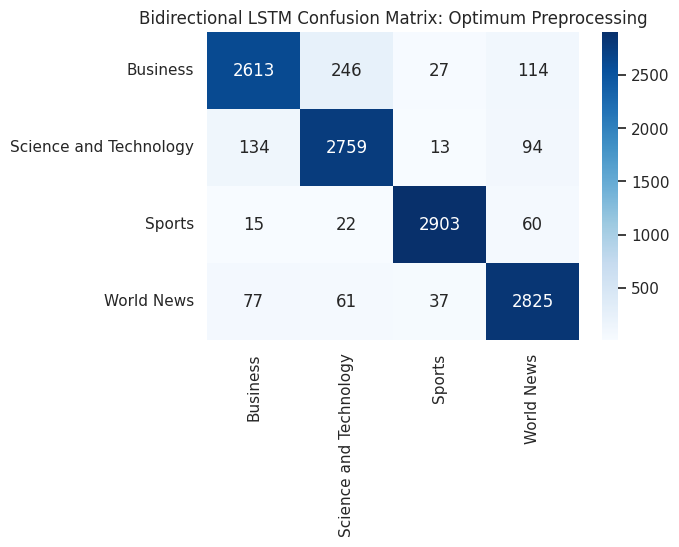

In [ ]:
from tensorflow.keras.layers import LSTM, Bidirectional
from tensorflow.keras.optimizers import RMSprop

with tf.device('/device:GPU:0'):
    for i in all_results[:]:
      if i['Model'] == 'Bidirectional LSTM':
        all_results.remove(i)

    for name, data in sequence_data.items():
        print(f"\n--- Training Bidirectional LSTM on: {name} ---")

        X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
            data['X_train'],
            y_train_labels,
            test_size=0.2,
            random_state=42,
            stratify=y_train_labels
        )

        model_rnn = Sequential([
            tf.keras.Input(shape=(max_len,)),
            Embedding(input_dim=data['num_words'],
                      output_dim=embedding_dim,
                      weights=[np.copy(data['embedding_matrix'])],
                      trainable=True),
            Bidirectional(LSTM(256)),
            Dense(128, activation='relu'),
            Dense(64, activation='relu'),
            Dense(4, activation='softmax')
        ])

        opt = RMSprop(learning_rate=0.001)
        model_rnn.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

        model_rnn.fit(
            X_train_seq_split,
            y_train_seq_split,
            validation_data=(X_val_seq_split, y_val_seq_split),
            epochs=50,
            batch_size=256,
            callbacks=[es],
            verbose=1
        )

        y_probs = model_rnn.predict(data['X_test'], verbose=0)
        y_pred = np.argmax(y_probs, axis=1)

        acc = accuracy_score(y_test_labels, y_pred)
        f1 = f1_score(y_test_labels, y_pred, average='macro')

        all_results.append({
            'Preprocessing': name,
            'Model': 'Bidirectional LSTM',
            'Accuracy': acc,
            'F1-Macro': f1
        })

        print(f"\nFinal Metrics for Bidirectional LSTM ({name}): Accuracy: {acc:.4f}, F1-Macro: {f1:.4f}")
        print(classification_report(y_test_labels, y_pred, target_names=le.classes_))

        cm = confusion_matrix(y_test_labels, y_pred)
        plt.figure(figsize=(6, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
        plt.title(f'Bidirectional LSTM Confusion Matrix: {name}')
        plt.show()

In [ ]:
import pandas as pd

# Create a summary DataFrame from all_results
final_comparison_df = pd.DataFrame(all_results)

# Sort by Accuracy to make it easier to see the ranking
final_comparison_df = final_comparison_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("Full Model Comparison (Sorted by Accuracy):")
display(final_comparison_df)

# Identify Best and Worst
best_model = final_comparison_df.iloc[0]
worst_model = final_comparison_df.iloc[-1]

print(f"\n--- Insights ---")
print(f"Best Performing Model: {best_model['Model']} with {best_model['Preprocessing']} (Accuracy: {best_model['Accuracy']:.4f}, F1: {best_model['F1-Macro']:.4f})")
print(f"Worst Performing Model: {worst_model['Model']} with {worst_model['Preprocessing']} (Accuracy: {worst_model['Accuracy']:.4f}, F1: {worst_model['F1-Macro']:.4f})")

Full Model Comparison (Sorted by Accuracy):


,Preprocessing,Model,Accuracy,F1-Macro
0,Optimum Preprocessing,Bidirectional LSTM,0.925000,0.924897
1,Optimum Preprocessing,LSTM,0.923750,0.923727
2,Extreme Preprocessing,Bidirectional GRU,0.921500,0.921857
3,Optimum Preprocessing,Bidirectional GRU,0.921167,0.921202
4,Extreme Preprocessing,LSTM,0.919917,0.919966
5,Extreme Preprocessing,Bidirectional LSTM,0.917417,0.917648
6,No Preprocessing,Bidirectional GRU,0.917417,0.917409
7,Extreme Preprocessing,GRU,0.916417,0.916689
8,No Preprocessing,Bidirectional LSTM,0.915417,0.915297
9,Optimum Preprocessing,GRU,0.914667,0.915007



--- Insights ---
Best Performing Model: Bidirectional LSTM with Optimum Preprocessing (Accuracy: 0.9250, F1: 0.9249)
Worst Performing Model: Logistic Regression with No Preprocessing (Accuracy: 0.8257, F1: 0.8260)


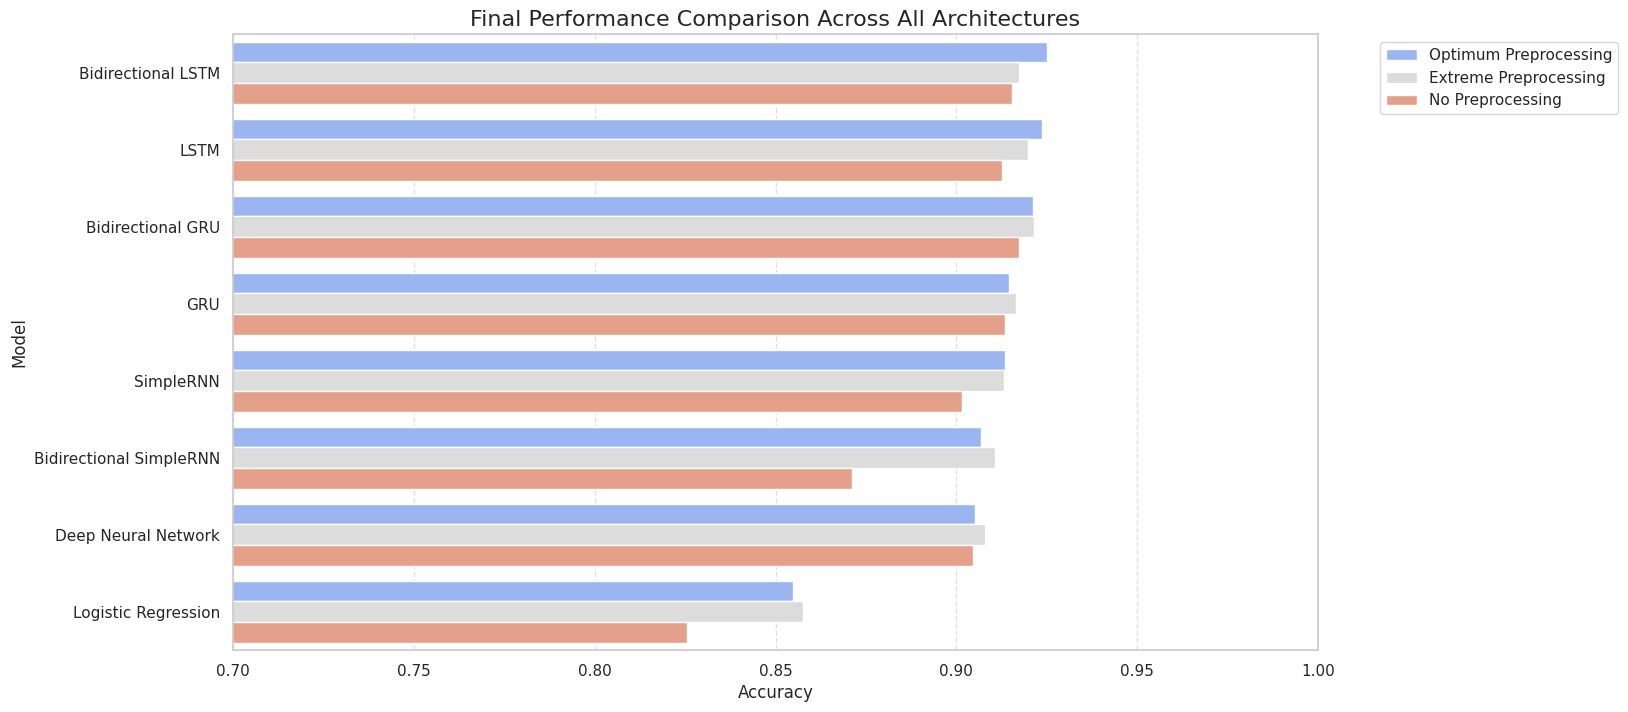

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizing the final results
plt.figure(figsize=(14, 8))
sns.barplot(data=final_comparison_df, x='Accuracy', y='Model', hue='Preprocessing', palette='coolwarm')
plt.title('Final Performance Comparison Across All Architectures', fontsize=16)
plt.xlim(0.7, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()